In [1]:
import random
import numpy as np
import torch

In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [3]:
def noisy_meshgrid_2d_regression(bounds: float, n_sqrt_mesh: int, input_noise: float):
    """
    Generate a 2D meshgrid for regression tasks.
    """
    
    # Create grid
    x = np.linspace(-bounds, bounds, n_sqrt_mesh)
    y = np.linspace(-bounds, bounds, n_sqrt_mesh)
    X, Y = np.meshgrid(x, y)

    # Noise levels
    input_noise = input_noise

    # Add noise to inputs
    X_noisy = X + input_noise * np.random.randn(*X.shape)
    Y_noisy = Y + input_noise * np.random.randn(*Y.shape)

    return X_noisy, Y_noisy

def sin_sqrt_surface_from_meshgrid(X: np.array, Y: np.array, output_noise: float):
    """
    Compute a surface from the given meshgrid.
    """

    R = np.divide(np.sqrt(X**2 + Y**2),0.9)
    F_clean = 0.5*np.sin(1+R)  

    # Add noise to output
    F_noisy = F_clean + output_noise * np.random.randn(*F_clean.shape)

    return F_noisy

Text(0.5, 0.92, 'sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

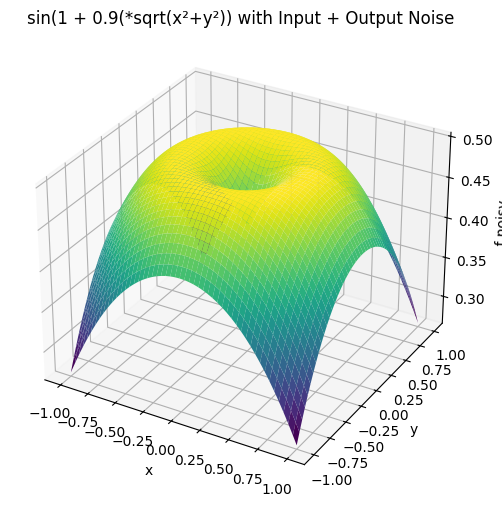

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Reproducibility
np.random.seed(42)

# Create grid
bounds = 1
n_sqrt_mesh = 50

# Noise levels
input_noise = 0.0
output_noise = 0.0

# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
F_noisy = sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise) 

# Plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_noisy, Y_noisy, F_noisy, cmap='viridis', edgecolor='none')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f noisy')
ax.set_title('sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

#plt.tight_layout()
#plt.show()

Text(0.5, 0.92, 'sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

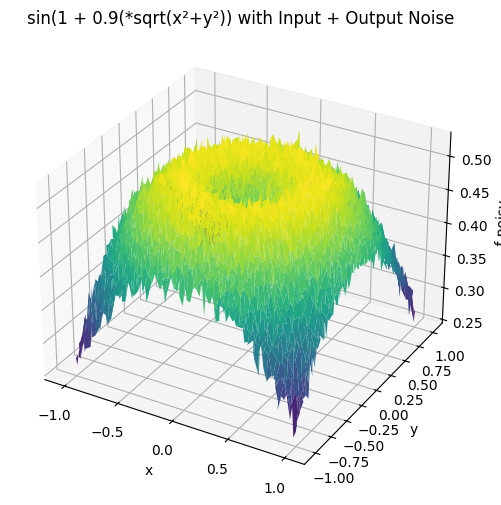

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


from mpl_toolkits.mplot3d import Axes3D

# Reproducibility
np.random.seed(42)

# Create grid
bounds = 1
n_sqrt_mesh = 50

# Noise levels
input_noise = 0.01
output_noise = 0.01

# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
F_noisy = sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise) 

# Plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(X_noisy, Y_noisy, F_noisy, cmap='viridis', edgecolor='none')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f noisy')
ax.set_title('sin(1 + 0.9(*sqrt(x²+y²)) with Input + Output Noise')

#plt.tight_layout()
#plt.show()

### **Toy Example 1:** Worst Case Kernel Size over Uniform Points in 3D Ball 

In [6]:
# Add noise to inputs
X_noisy, Y_noisy = noisy_meshgrid_2d_regression(bounds, n_sqrt_mesh, input_noise)

# Compute function with noisy inputs
tuples = np.vstack([X_noisy.ravel(), Y_noisy.ravel()]).T # sin_sqrt_surface_from_meshgrid(X_noisy, Y_noisy, output_noise))

final_tuples = [(np.array([x, y]), sin_sqrt_surface_from_meshgrid(x, y, output_noise)) for x, y in zip(X_noisy.ravel(), Y_noisy.ravel())]

print(np.array(final_tuples[1][-1:][0]))

0.2757854242477074


In [7]:
def compute_K_feasible_set_tuples(K, tuples, d_in, d_out, p_2, epsilon_1, epsilon_2):
    """
    Implements the iterative algorithm for estimating feasible sets for one input point based on possible target data points for a noisy inverse problem. 
    
    Args:
        - tuples: data with input and target data in tuples, target data is assumed to be d_out=1
        - d_in: dimension of input data points in tuples
        - p_2: Order of the norm on the target dataset $\mathcal{M}_2$. Set to p=2 for the ell 2 norm computation.
        - epsilon_1: Noise level in the input data.
        - epsilon_2: Noise level in the output data.

    Returns:
        - feas_set_y: approximation to the feasible set, consisting of all target data points that can be in a tuple with an input data point within the noise level.
    """
    feasible_sets_list=[]

    for k in range(K):
        # Compute feasible set for input data of tuple f_M
        f_M= tuples[k]
        feas_set_M = []
        for f_n in tuples:
            e_n = f_n[:(d_in-1)][0] - f_M[:(d_in-1)][0] # Compute noise vector on input data 

            if np.linalg.norm(e_n,p_2) <= epsilon_1:  # Check if noise is below noiselevel
                # add traget data point f_n to feasible set
                feas_set_M.append(f_n[-d_out:][0])

            e_o = np.array(f_n[-d_out:][0] - f_M[-d_out:][0]) # Compute noise vector on output data

            if np.abs(e_o) <= epsilon_2:  # Check if noise is below noiselevel
                # add traget data point f_n to feasible set
                feas_set_M.append(f_n[-d_out:][0])

        feasible_sets_list.append(feas_set_M)

    return feasible_sets_list

<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/gs/9cgd6jx162sdgf_zsbw6vddw0000gp/T/ipykernel_12204/1594977589.py:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  - p_2: Order of the norm on the target dataset $\mathcal{M}_2$. Set to p=2 for the ell 2 norm computation.


In [ ]:
p_2 = 2
K = 10
feasible_sets_list = compute_K_feasible_set_tuples(K, final_tuples, d_in=2, d_out=1, p_2=2, epsilon_1=input_noise, epsilon_2=output_noise)

In [9]:
print(len(feasible_sets_list))

100


In [10]:
K = len(feasible_sets_list)
av_ker= 0
M =0
feas_avs = []
for feas in feasible_sets_list:
    av_feas= 0
    for x in feas:
        for y in feas:
            av_feas += np.power(np.abs(x-y),2)
    if len(feas) > 1:
        av_feas = av_feas/(len(feas)-1)
        M += len(feas)
    else:
        av_feas = 0
    av_ker += av_feas

av_ker = np.power(av_ker/M, 1/2)

print(av_ker)

KeyboardInterrupt: 